<a href="https://colab.research.google.com/github/WijayaPrat/CNN-Facial-Emotion-Recognition-using-CNN/blob/master/Profitability_Analysis_%7C_Data_Analyst_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload File

In [ ]:
import pandas as pd
import statsmodels.api as sm
from google.colab import files

# ===============================
# Upload File
# ===============================
print("Silakan upload file Excel (.xlsx) atau CSV (.csv)")
uploaded = files.upload()

# Ambil nama file pertama yang diupload
file_name = next(iter(uploaded.keys()))
print(f"\nFile berhasil diupload: {file_name}")

# ===============================
# Baca File
# ===============================
try:
    if file_name.lower().endswith(".xlsx"):
        df = pd.read_excel(file_name)
    elif file_name.lower().endswith(".csv"):
        df = pd.read_csv(file_name)
    else:
        raise ValueError("Format file harus .xlsx atau .csv")
except Exception as e:
    raise Exception(f"Gagal membaca file:\n{e}")

# ===============================
# Tampilkan Informasi Dataset
# ===============================
print("\nJumlah data :", len(df))
print("\nKolom yang tersedia:")
print(list(df.columns))

# ===============================
# Cek Kolom
# ===============================
required_columns = ["Sales", "Profit"]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(
        f"""
Kolom berikut tidak ditemukan:
{missing}

Kolom yang tersedia:
{list(df.columns)}
"""
    )


Silakan upload file Excel (.xlsx) atau CSV (.csv)


Saving Superstore_Cleaned_ML.xlsx to Superstore_Cleaned_ML.xlsx

File berhasil diupload: Superstore_Cleaned_ML.xlsx

Jumlah data : 51290

Kolom yang tersedia:
['Row ID', 'Order ID', 'Customer ID', 'Customer Name', 'Product ID', 'Product Name', 'Category', 'Sub-Category', 'Segment', 'Country', 'City', 'State', 'Region', 'Market', 'Market Group', 'Ship Mode', 'Order Priority', 'Order Date', 'Ship Date', 'Shipping Duration (Days)', 'Year', 'Week Number', 'Sales', 'Quantity', 'Discount', 'Shipping Cost', 'Profit']


Cleansing data

In [ ]:
# Mengecek jumlah data duplikat

duplicate_count = df.duplicated().sum()

print("Jumlah data duplikat :", duplicate_count)
print(f"Persentase           : {duplicate_count/len(df)*100:.2f}%")

Jumlah data duplikat : 0
Persentase           : 0.00%


In [ ]:
df.describe()

,Row ID,Order Date,Ship Date,Shipping Duration (Days),Year,Week Number,Sales,Quantity,Discount,Shipping Cost,Profit
count,51290.00000,51290,51290,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,25645.50000,2013-05-11 21:26:49.155780864,2013-05-15 20:42:42.745174784,3.969370,2012.777208,31.287112,246.498440,3.476545,0.142908,26.375818,28.610982
min,1.00000,2011-01-01 00:00:00,2011-01-03 00:00:00,0.000000,2011.000000,1.000000,0.000000,1.000000,0.000000,0.002000,-6599.978000
25%,12823.25000,2012-06-19 00:00:00,2012-06-23 00:00:00,3.000000,2012.000000,20.000000,31.000000,2.000000,0.000000,2.610000,0.000000
50%,25645.50000,2013-07-08 00:00:00,2013-07-12 00:00:00,4.000000,2013.000000,33.000000,85.000000,3.000000,0.000000,7.790000,9.240000
75%,38467.75000,2014-05-22 00:00:00,2014-05-26 00:00:00,5.000000,2014.000000,44.000000,251.000000,5.000000,0.200000,24.450000,36.810000
max,51290.00000,2014-12-31 00:00:00,2015-01-07 00:00:00,7.000000,2014.000000,53.000000,22638.000000,14.000000,0.850000,933.570000,8399.976000
std,14806.29199,NaN,NaN,1.729437,1.098931,14.429795,487.567175,2.278766,0.212280,57.296810,174.340972


In [ ]:
print(df.columns)

Index(['Row ID', 'Order ID', 'Customer ID', 'Customer Name', 'Product ID',
       'Product Name', 'Category', 'Sub-Category', 'Segment', 'Country',
       'City', 'State', 'Region', 'Market', 'Market Group', 'Ship Mode',
       'Order Priority', 'Order Date', 'Ship Date', 'Shipping Duration (Days)',
       'Year', 'Week Number', 'Sales', 'Quantity', 'Discount', 'Shipping Cost',
       'Profit'],
      dtype='object')


In [ ]:
for col in df.columns:
    print(col)

Row ID
Order ID
Customer ID
Customer Name
Product ID
Product Name
Category
Sub-Category
Segment
Country
City
State
Region
Market
Market Group
Ship Mode
Order Priority
Order Date
Ship Date
Shipping Duration (Days)
Year
Week Number
Sales
Quantity
Discount
Shipping Cost
Profit


EDA

In [ ]:
# [EDA-1] Statistik target (Profit) & tingkat kerugian
print(df["Profit"].describe())

loss_rate = (df["Profit"] < 0).mean()
print(f"\n>> Transaksi merugi : {loss_rate:.2%} ({(df['Profit']<0).sum():,} baris)")
print(f">> Total profit     : {df['Profit'].sum():,.0f}")
print(f">> Total kerugian   : {df.loc[df['Profit']<0,'Profit'].sum():,.0f}")

count    51290.000000
mean        28.610982
std        174.340972
min      -6599.978000
25%          0.000000
50%          9.240000
75%         36.810000
max       8399.976000
Name: Profit, dtype: float64

>> Transaksi merugi : 24.46% (12,544 baris)
>> Total profit     : 1,467,457
>> Total kerugian   : -920,646


In [ ]:
# [EDA-3] Profit per Sub-Category (terburuk → terbaik)
sub = df.groupby("Sub-Category")["Profit"].agg(["sum","mean"]).sort_values("sum")
sub

,sum,mean
Sub-Category,,
Tables,-64083.38870,-74.429023
Fasteners,11525.42410,4.762572
Labels,15010.51200,5.759982
Supplies,22583.26310,9.312686
Envelopes,29601.11630,12.156516
Furnishings,46967.42550,14.816223
Art,57953.91090,11.868505
Machines,58867.87300,39.614989
Paper,59207.68270,16.734789


In [ ]:
# fitur engineering
mkt = df.groupby("Market").agg(sales=("Sales","sum"), profit=("Profit","sum"))
mkt["margin_%"] = mkt["profit"] / mkt["sales"] * 100
mkt.sort_values("profit", ascending=False)

,sales,profit,margin_%
Market,,,
APAC,3585833,436000.04900,12.158961
EU,2938139,372829.74150,12.689316
US,2297354,286397.02170,12.466386
LATAM,2164687,221643.48708,10.239055
Africa,783776,88871.63100,11.338907
EMEA,806184,43897.97100,5.445155
Canada,66932,17817.39000,26.620137


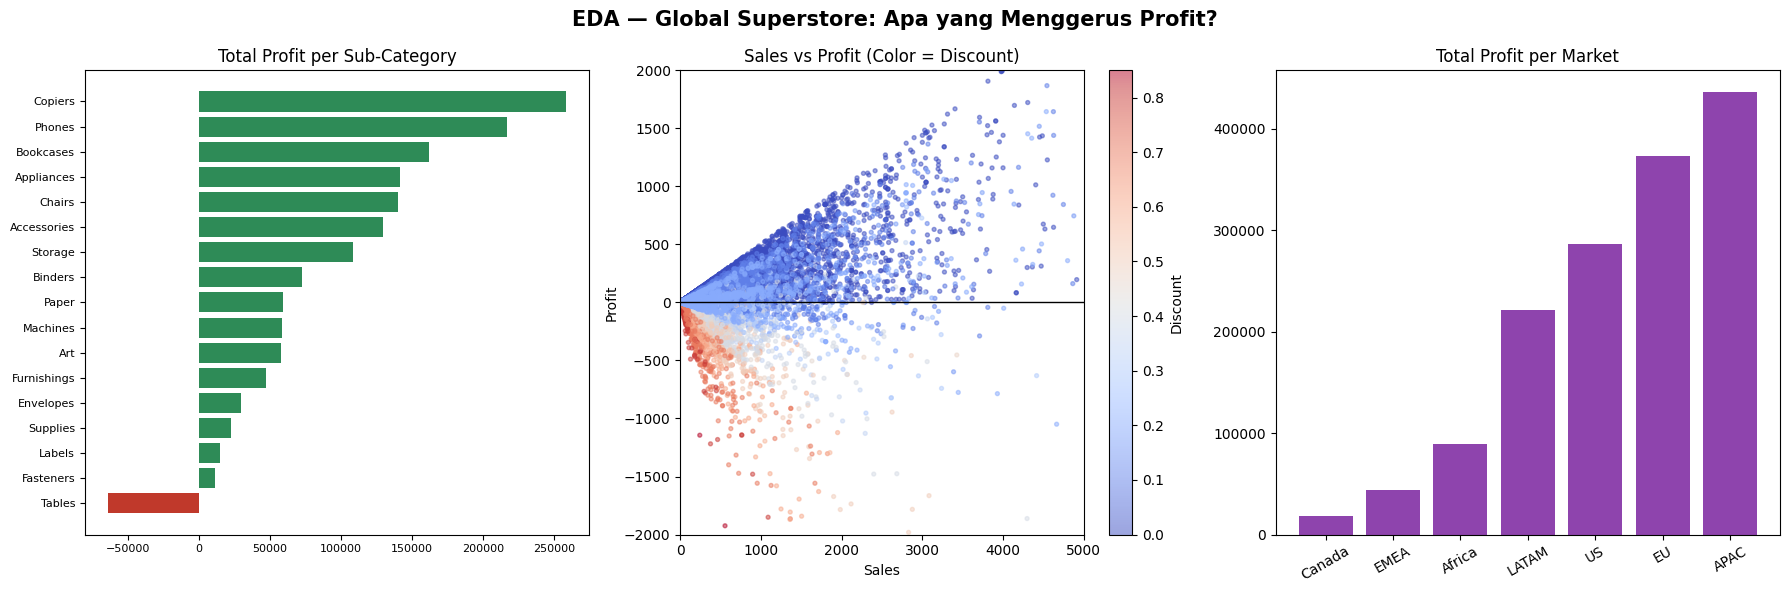

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============ EDA VISUALISASI UTAMA ============
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    "EDA — Global Superstore: Apa yang Menggerus Profit?",
    fontsize=15,
    fontweight="bold"
)

# (1) Total Profit per Sub-Category
s = df.groupby("Sub-Category")["Profit"].sum().sort_values()
ax[0].barh(
    s.index,
    s.values,
    color=["#c0392b" if v < 0 else "#2e8b57" for v in s.values]
)
ax[0].set_title("Total Profit per Sub-Category")
ax[0].tick_params(labelsize=8)

# (2) Sales vs Profit (warna = Diskon)
sc = ax[1].scatter(
    df["Sales"],
    df["Profit"],
    c=df["Discount"],
    cmap="coolwarm",
    s=8,
    alpha=0.5
)
ax[1].axhline(0, color="black", lw=1)
ax[1].set_xlim(0, 5000)
ax[1].set_ylim(-2000, 2000)
ax[1].set_title("Sales vs Profit (Color = Discount)")
ax[1].set_xlabel("Sales")
ax[1].set_ylabel("Profit")
plt.colorbar(sc, ax=ax[1], label="Discount")

# (3) Total Profit per Market
m = df.groupby("Market")["Profit"].sum().sort_values()
ax[2].bar(
    m.index,
    m.values,
    color="#8e44ad"
)
ax[2].set_title("Total Profit per Market")
ax[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

outlier

In [ ]:
# Menghitung jumlah outlier tiap kolom
num_cols = ["Sales", "Profit","Shipping Cost"]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}")
    print(f"Jumlah Outlier : {len(outlier)}")
    print(f"Persentase     : {len(outlier)/len(df)*100:.2f}%")
    print("-"*40)

Sales
Jumlah Outlier : 5655
Persentase     : 11.03%
----------------------------------------
Profit
Jumlah Outlier : 9755
Persentase     : 19.02%
----------------------------------------
Shipping Cost
Jumlah Outlier : 5909
Persentase     : 11.52%
----------------------------------------


Model ML

In [ ]:
# ===============================
# Persiapan Data
# ===============================
X = df[["Sales"]].astype(float)
y = df["Profit"].astype(float)

# Tambahkan konstanta
X = sm.add_constant(X)

# ===============================
# Bangun Model Regresi
# ===============================
model = sm.OLS(y, X).fit()

# ===============================
# Hasil Regresi
# ===============================
print("\n" + "="*70)
print("HASIL REGRESI LINEAR")
print("="*70)
print(model.summary())

# ===============================
# Persamaan Regresi
# ===============================
intercept = model.params["const"]
coef = model.params["Sales"]

print("\nPersamaan Regresi:")
print(f"Profit = {intercept:.4f} + ({coef:.4f} × Sales)")

print("\nR-squared :", round(model.rsquared, 4))
print("Adjusted R-squared :", round(model.rsquared_adj, 4))
print("P-value Sales :", model.pvalues["Sales"])


HASIL REGRESI LINEAR
                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.235
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                 1.577e+04
Date:                Fri, 17 Jul 2026   Prob (F-statistic):               0.00
Time:                        13:44:24   Log-Likelihood:            -3.3061e+05
No. Observations:               51290   AIC:                         6.612e+05
Df Residuals:                   51288   BIC:                         6.612e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -14.1307      0.7